# EDA on Insurance Claims

**Name**: Uday Raj

## Boilerplate

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [3]:
df1 = pd.read_csv('insurance_data.csv')

In [4]:
df = df1.copy()

In [5]:
df.set_index('index')

,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
index,,,,,,,,,,
0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87
1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51
2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94
3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40
4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01
...,...,...,...,...,...,...,...,...,...,...
1335,1336,44.0,female,35.5,88,Yes,0,Yes,northwest,55135.40
1336,1337,59.0,female,38.1,120,No,1,Yes,northeast,58571.07
1337,1338,30.0,male,34.5,91,Yes,3,Yes,northwest,60021.40


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          1340 non-null   int64  
 1   PatientID      1340 non-null   int64  
 2   age            1335 non-null   float64
 3   gender         1340 non-null   object 
 4   bmi            1340 non-null   float64
 5   bloodpressure  1340 non-null   int64  
 6   diabetic       1340 non-null   object 
 7   children       1340 non-null   int64  
 8   smoker         1340 non-null   object 
 9   region         1337 non-null   object 
 10  claim          1340 non-null   float64
dtypes: float64(3), int64(4), object(4)
memory usage: 115.3+ KB


## Univariate Analysis


#### Age
**Conclusion** 
- There are 5 missing values in Age
- Make a new column which tell the patient is young midage or old (FE)

In [7]:
df['age'].isnull().sum().item()

5

In [8]:
df['age'].describe()

count    1335.000000
mean       38.078652
std        11.102924
min        18.000000
25%        29.000000
50%        38.000000
75%        47.000000
max        60.000000
Name: age, dtype: float64

In [9]:
df['age'].value_counts()

age
43.0    50
26.0    47
46.0    44
30.0    44
32.0    44
40.0    42
27.0    41
37.0    41
48.0    40
45.0    40
29.0    39
34.0    39
49.0    38
31.0    38
42.0    37
47.0    37
36.0    37
35.0    36
28.0    36
44.0    35
33.0    35
50.0    32
38.0    32
25.0    32
19.0    29
23.0    28
55.0    26
20.0    26
39.0    26
41.0    24
22.0    24
59.0    22
57.0    21
60.0    21
21.0    18
52.0    18
56.0    18
54.0    17
51.0    17
58.0    17
24.0    16
18.0    16
53.0    15
Name: count, dtype: int64

<Axes: ylabel='Frequency'>

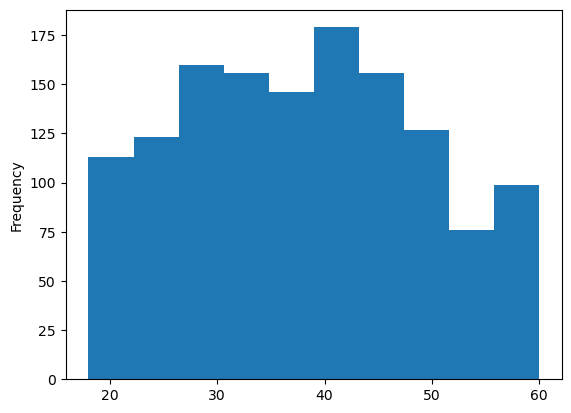

In [10]:
df['age'].plot(kind='hist')

<Axes: ylabel='Density'>

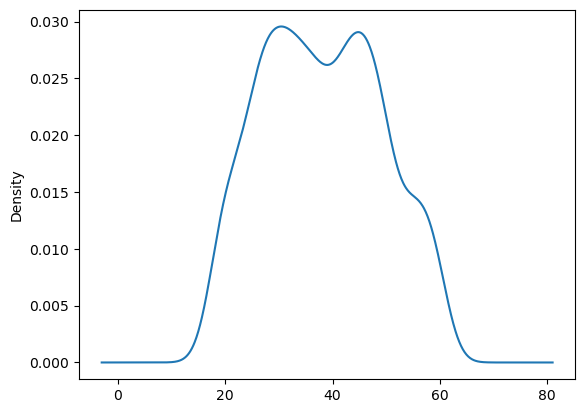

In [11]:
df['age'].plot(kind='kde')

<Axes: >

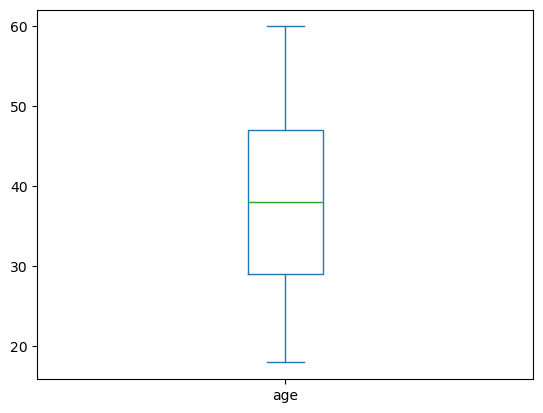

In [12]:
df['age'].plot(kind='box') # there is no outlier

In [13]:
df['age'].skew()

np.float64(0.11361133741072633)

#### Insurance Claim
**Conclusion**
- There is no any missing value means all of patient take the insurance
- There is more patient in range of 0 - 15k claim

In [14]:
df['claim'].isnull().sum().item()

0

In [15]:
df['claim'].describe()

count     1340.000000
mean     13252.745642
std      12109.609288
min       1121.870000
25%       4719.685000
50%       9369.615000
75%      16604.305000
max      63770.430000
Name: claim, dtype: float64

<Axes: ylabel='Frequency'>

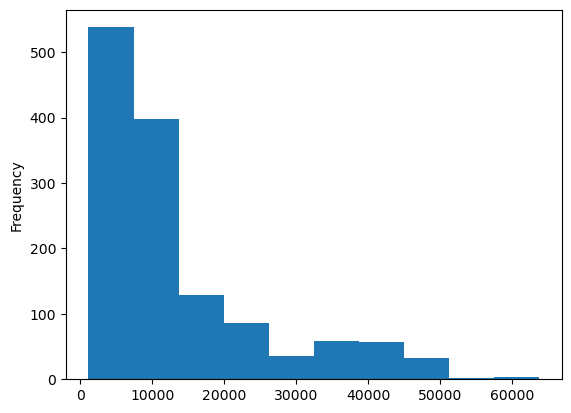

In [16]:
df['claim'].plot(kind='hist')

<Axes: ylabel='Density'>

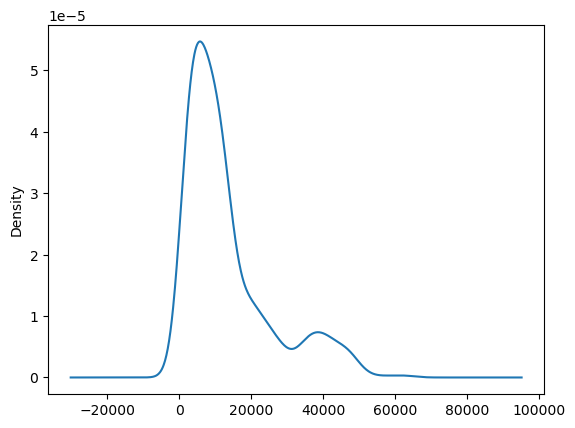

In [17]:
df['claim'].plot(kind='kde')

<Axes: >

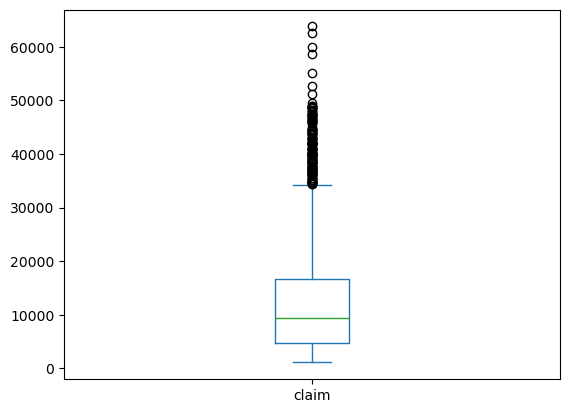

In [18]:
df['claim'].plot(kind='box')

In [19]:
df[df['claim'] > 50000] 

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
1333,1333,1334,44.0,male,36.4,127,No,1,Yes,southwest,51194.56
1334,1334,1335,43.0,male,32.8,125,No,0,Yes,southwest,52590.83
1335,1335,1336,44.0,female,35.5,88,Yes,0,Yes,northwest,55135.40
1336,1336,1337,59.0,female,38.1,120,No,1,Yes,northeast,58571.07
1337,1337,1338,30.0,male,34.5,91,Yes,3,Yes,northwest,60021.40
1338,1338,1339,37.0,male,30.4,106,No,0,Yes,southeast,62592.87
1339,1339,1340,30.0,female,47.4,101,No,0,Yes,southeast,63770.43


In [20]:
df['claim'].skew().item()

1.5167468509489237

#### BMI (Body Mass Index)
- Under 18.5: Underweight
- 18.5 to 24.9: Normal/Healthy weight
- 25.0 to 29.9: Overweight
- 30.0 and above: Obese
  
**Conclusion**
- Make a new col for healthy_type (FE)
- Avg patient is the obese (more fat)

In [21]:
df['bmi'].isnull().sum().item()

0

In [22]:
df['bmi'].value_counts()

bmi
33.3    17
27.6    17
28.9    16
32.3    15
29.8    14
        ..
17.9     1
21.0     1
50.4     1
49.1     1
47.4     1
Name: count, Length: 275, dtype: int64

In [23]:
df['bmi'].value_counts()

bmi
33.3    17
27.6    17
28.9    16
32.3    15
29.8    14
        ..
17.9     1
21.0     1
50.4     1
49.1     1
47.4     1
Name: count, Length: 275, dtype: int64

In [24]:
df['bmi'].describe()

count    1340.000000
mean       30.668955
std         6.106735
min        16.000000
25%        26.275000
50%        30.400000
75%        34.700000
max        53.100000
Name: bmi, dtype: float64

<Axes: ylabel='Frequency'>

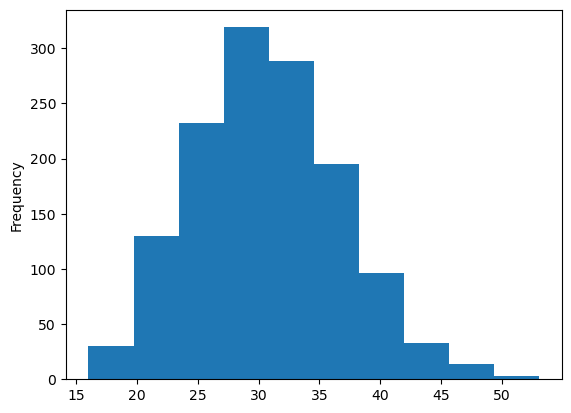

In [25]:
df['bmi'].plot(kind='hist')

<Axes: ylabel='Density'>

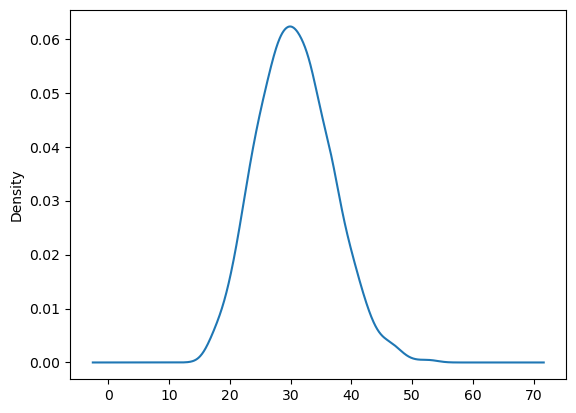

In [26]:
df['bmi'].plot(kind='kde')

<Axes: >

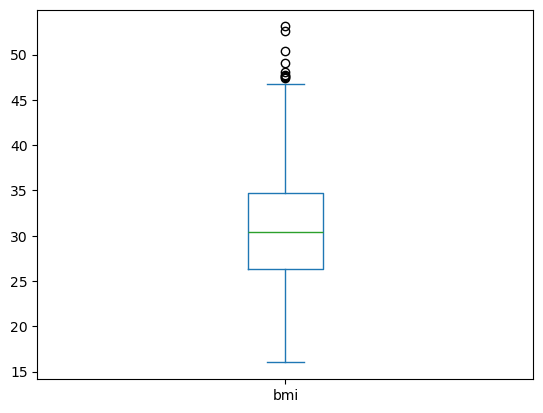

In [27]:
df['bmi'].plot(kind='box')

In [28]:
df['bmi'].skew().item()

0.28597245020808587

In [29]:
df[df['bmi'] > 50]

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
9,9,10,30.0,male,53.1,97,No,0,No,northwest,1163.46
141,141,142,46.0,male,50.4,89,Yes,1,No,southeast,2438.06
1299,1299,1300,50.0,male,52.6,110,No,1,Yes,southeast,44501.40


#### Blood Pressure
- Normal (Below 120)
- Elevated (120–129)
- Stage 1 (130–139)
- Stage 2 (140–179)
- Crisis (180 or Higher)

**Conclusion**
- Make a new col for the BP_type (FE)


In [30]:
df['bloodpressure'].value_counts()

bloodpressure
91     62
80     59
88     58
89     58
81     58
       ..
138     1
116     1
134     1
121     1
133     1
Name: count, Length: 61, dtype: int64

In [31]:
df['bloodpressure'].isnull().sum().item()

0

In [32]:
df['bloodpressure'].describe()

count    1340.000000
mean       94.157463
std        11.434712
min        80.000000
25%        86.000000
50%        92.000000
75%        99.000000
max       140.000000
Name: bloodpressure, dtype: float64

In [33]:
df['bloodpressure'].skew().item()

1.4835342102293079

<Axes: ylabel='Frequency'>

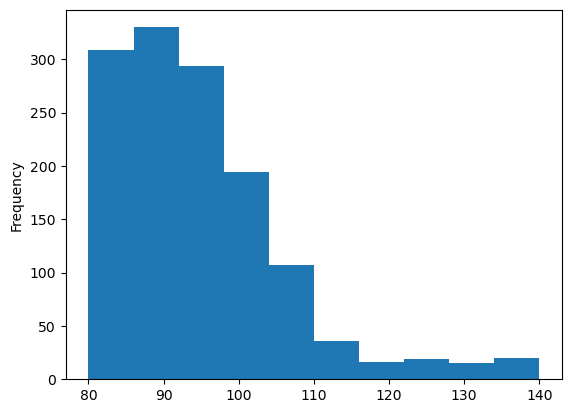

In [34]:
df['bloodpressure'].plot(kind='hist')

<Axes: ylabel='Density'>

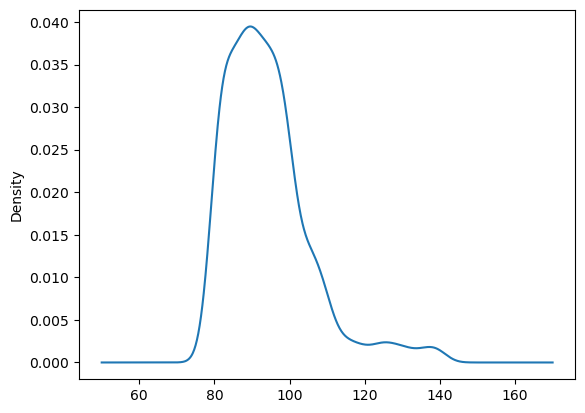

In [35]:
df['bloodpressure'].plot(kind='kde')


<Axes: >

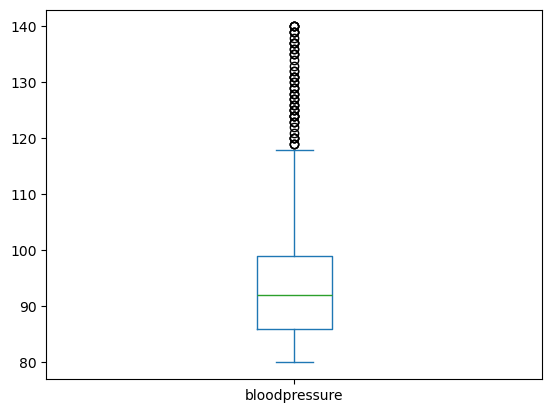

In [36]:
df['bloodpressure'].plot(kind='box')

In [37]:
(df['bloodpressure'] > 130).sum().item()

27

In [38]:
df[df['bloodpressure'] > 130] 

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
1150,1150,1151,55.0,female,27.1,135,No,1,No,southwest,26140.36
1156,1156,1157,46.0,female,23.0,137,Yes,0,Yes,southeast,27037.91
1161,1161,1162,22.0,male,22.4,137,Yes,2,No,northeast,27375.90
1174,1174,1175,44.0,female,29.1,139,No,0,Yes,northwest,29141.36
1181,1181,1182,32.0,male,28.6,132,No,0,No,northeast,30260.00
1196,1196,1197,36.0,female,31.4,136,Yes,0,Yes,southwest,34166.27
1197,1197,1198,30.0,male,31.1,136,No,0,Yes,northeast,34254.05
1210,1210,1211,25.0,male,30.8,140,Yes,0,Yes,southwest,35491.64
1216,1216,1217,34.0,female,36.9,131,No,0,Yes,southeast,36149.48
1220,1220,1221,32.0,male,38.2,135,Yes,0,Yes,southeast,36307.80


#### Children
- Single (0 children / Family Size = 1)
- Small (1 to 2 children / Family Size = 2–3)
- Large (3 to 5 children / Family Size = 4–6)

**Conclusion**
- Make two new col with family_size and family type
- 1/4 of the either have no kids or single


In [39]:
df['children'].isnull().sum().item()

0

In [40]:
df['children'].describe()

count    1340.000000
mean        1.093284
std         1.205334
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         5.000000
Name: children, dtype: float64

In [41]:
df['children'].skew()

np.float64(0.9402991133470963)

<Axes: ylabel='Frequency'>

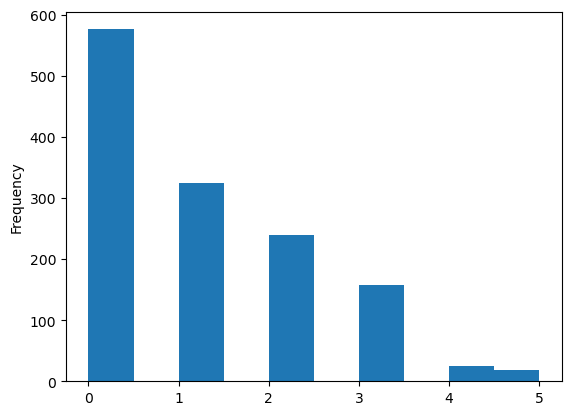

In [42]:
df['children'].plot(kind='hist')

<Axes: ylabel='Density'>

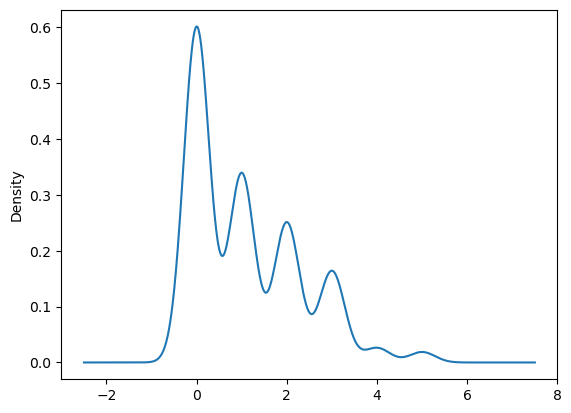

In [43]:
df['children'].plot(kind='kde')

<Axes: >

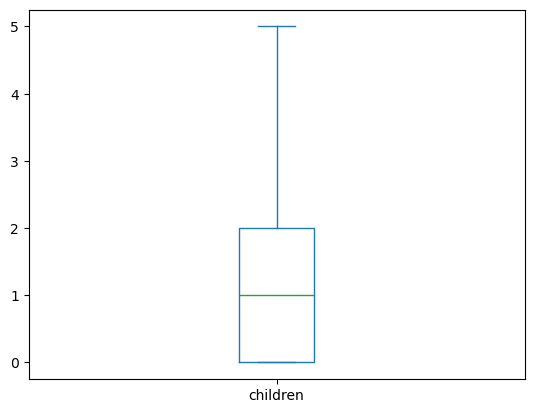

In [44]:
df['children'].plot(kind='box')

#### Gender
**Coclusion**
- Male are slightly more than than female (1.2% more)

In [45]:
df

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
0,0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87
1,1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01
...,...,...,...,...,...,...,...,...,...,...,...
1335,1335,1336,44.0,female,35.5,88,Yes,0,Yes,northwest,55135.40
1336,1336,1337,59.0,female,38.1,120,No,1,Yes,northeast,58571.07
1337,1337,1338,30.0,male,34.5,91,Yes,3,Yes,northwest,60021.40
1338,1338,1339,37.0,male,30.4,106,No,0,Yes,southeast,62592.87


In [46]:
df['gender'].value_counts()

gender
male      678
female    662
Name: count, dtype: int64

In [47]:
df['gender'].isnull().sum().item()

0

<Axes: ylabel='count'>

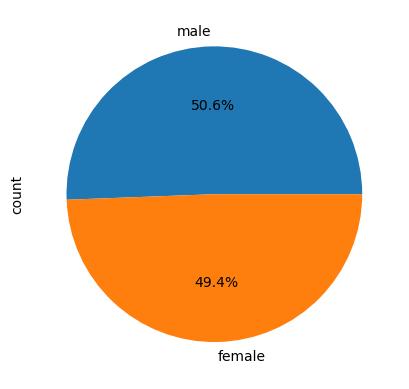

In [48]:
df['gender'].value_counts().plot(kind='pie', autopct='%0.1f%%')

<Axes: xlabel='gender'>

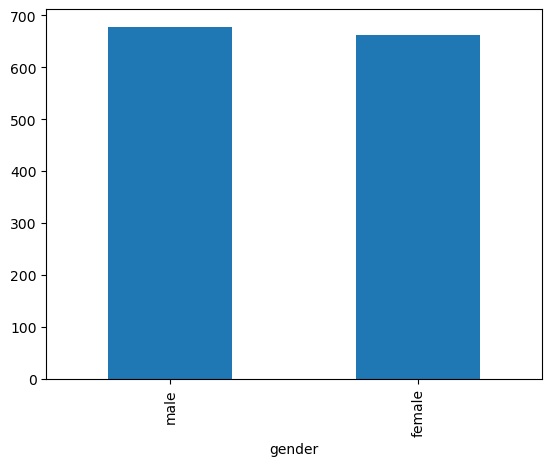

In [49]:
df['gender'].value_counts().plot(kind='bar')

#### Diabetic
**Conclusion**
- More than half people are not diabetic

In [50]:
df['diabetic'].isnull().sum().item()

0

<Axes: ylabel='count'>

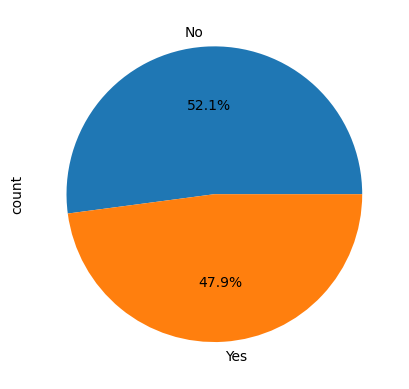

In [51]:
df['diabetic'].value_counts().plot(kind='pie',autopct='%0.1f%%')

<Axes: xlabel='diabetic'>

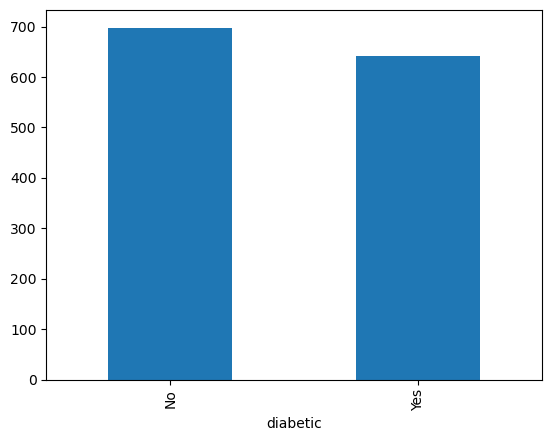

In [52]:
df['diabetic'].value_counts().plot(kind='bar')

#### Smoker
**Conclusion**
- 2/3rd are non diabetios



In [53]:
df['smoker'].value_counts()

smoker
No     1066
Yes     274
Name: count, dtype: int64

<Axes: ylabel='count'>

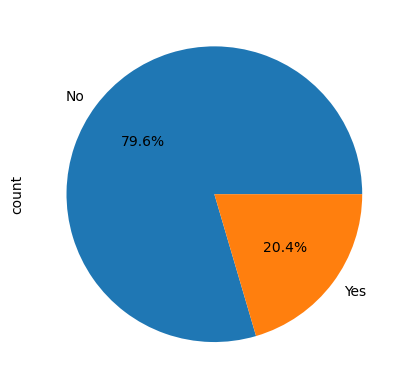

In [54]:
df['smoker'].value_counts().plot(kind='pie', autopct='%0.1f%%')

<Axes: xlabel='smoker'>

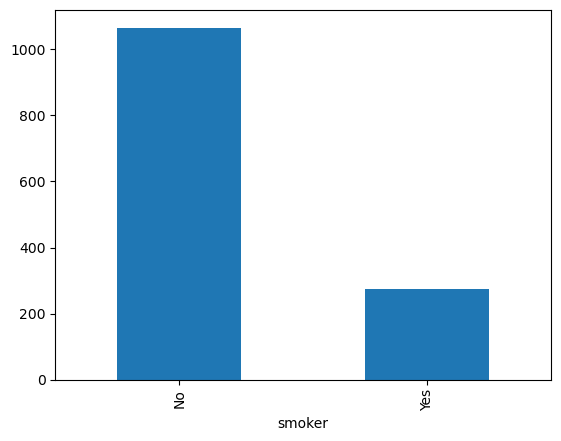

In [55]:
df['smoker'].value_counts().plot(kind='bar')

#### Region
**Conclusion**
- More people are from the southeast

In [56]:
df['region'].isnull().sum().item()

3

In [57]:
df['region'].value_counts()

region
southeast    443
northwest    349
southwest    314
northeast    231
Name: count, dtype: int64

<Axes: xlabel='region'>

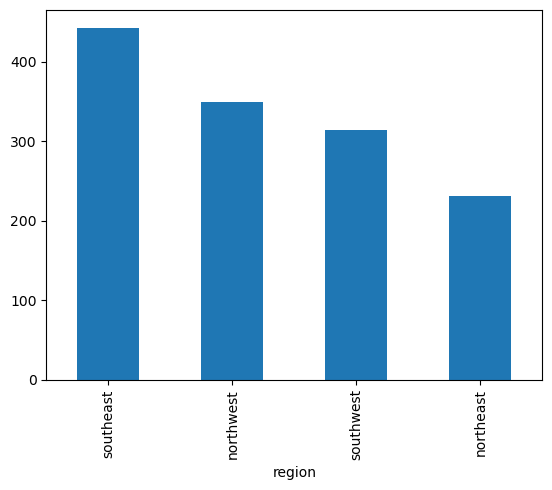

In [58]:
df['region'].value_counts().plot(kind='bar')

<Axes: ylabel='count'>

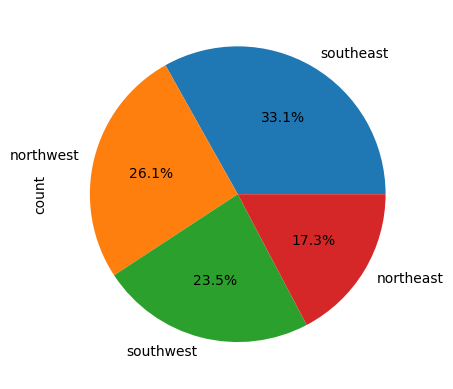

In [59]:
df['region'].value_counts().plot(kind='pie', autopct='%0.1f%%')

## Feature Engineering

In [67]:
# age

In [71]:
# in the age there are some value are missing (5 are the missing valueabs)
df['age'].isnull().sum().item()

5

In [86]:
# if age is the less than 18 means not adult --- N (No)
# if age is the more than 18 means adult ---  Y (yes}
 
def isadult(age):
    if age < 18:
        return 'N'
    else:
        return 'Y'

In [87]:
df['is_adult'] = df['age'].apply(isadult)

In [88]:
# Conclusion 
 # - There is no any patient whose age is the less than the 18

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim,is_adult
0,0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87,Y
1,1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51,Y
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94,Y
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40,Y
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
1335,1335,1336,44.0,female,35.5,88,Yes,0,Yes,northwest,55135.40,Y
1336,1336,1337,59.0,female,38.1,120,No,1,Yes,northeast,58571.07,Y
1337,1337,1338,30.0,male,34.5,91,Yes,3,Yes,northwest,60021.40,Y
1338,1338,1339,37.0,male,30.4,106,No,0,Yes,southeast,62592.87,Y


In [89]:
# BMI (Body Mass Index) type

In [91]:
df['bmi'].isnull().sum()

np.int64(0)

In [92]:
def bmi_type(bmi):

    if bmi < 18.5:
        return 'underweight'
    elif bmi >= 18.5 and bmi <= 24.9:
        return 'healthy'
    elif bmi >= 25 and bmi <= 29.9:
        return 'overwieght'
    else:
        return 'obese'

In [99]:
df['bmi_type'] = df['bmi'].apply(bmi_type)

In [102]:
df['bmi_type'].value_counts()

bmi_type
obese          708
overwieght     389
healthy        223
underweight     20
Name: count, dtype: int64

In [101]:
# Blood pressure type

In [106]:
df['bloodpressure'].isnull().sum()

np.int64(0)

In [109]:
def bp_type(bp):
    if bp < 120:
        return 'normal'
    elif bp >= 120 and bp <= 129:
        return 'elevated'
    elif bp >= 130 and bp <= 139:
        return 'stage_1'
    elif bp >= 140 and bp <= 179:
        return 'stage_2'
    else: 
        return 'crisis'

In [114]:
df['bp_type'] = df['bloodpressure'].apply(bp_type)

In [115]:
df

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim,is_adult,bmi_type,bp_type
0,0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87,Y,healthy,normal
1,1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51,Y,obese,normal
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94,Y,obese,normal
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40,Y,obese,normal
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01,Y,obese,normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1335,1335,1336,44.0,female,35.5,88,Yes,0,Yes,northwest,55135.40,Y,obese,normal
1336,1336,1337,59.0,female,38.1,120,No,1,Yes,northeast,58571.07,Y,obese,elevated
1337,1337,1338,30.0,male,34.5,91,Yes,3,Yes,northwest,60021.40,Y,obese,normal
1338,1338,1339,37.0,male,30.4,106,No,0,Yes,southeast,62592.87,Y,obese,normal


In [116]:
df['bp_type'].value_counts()

bp_type
normal      1281
elevated      30
stage_1       24
stage_2        5
Name: count, dtype: int64

In [62]:
df

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
0,0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87
1,1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01
...,...,...,...,...,...,...,...,...,...,...,...
1335,1335,1336,44.0,female,35.5,88,Yes,0,Yes,northwest,55135.40
1336,1336,1337,59.0,female,38.1,120,No,1,Yes,northeast,58571.07
1337,1337,1338,30.0,male,34.5,91,Yes,3,Yes,northwest,60021.40
1338,1338,1339,37.0,male,30.4,106,No,0,Yes,southeast,62592.87


In [ ]:
# children --

In [119]:
df['children'].isnull().sum()

np.int64(0)

In [120]:
def family_size(child):
    return child + 1

In [123]:
df['family_size'] = df['children'].apply(family_size)

In [124]:
df

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim,is_adult,bmi_type,bp_type,family_size
0,0,1,39.0,male,23.2,91,Yes,0,No,southeast,1121.87,Y,healthy,normal,1
1,1,2,24.0,male,30.1,87,No,0,No,southeast,1131.51,Y,obese,normal,1
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94,Y,obese,normal,1
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40,Y,obese,normal,1
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01,Y,obese,normal,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1335,1335,1336,44.0,female,35.5,88,Yes,0,Yes,northwest,55135.40,Y,obese,normal,1
1336,1336,1337,59.0,female,38.1,120,No,1,Yes,northeast,58571.07,Y,obese,elevated,2
1337,1337,1338,30.0,male,34.5,91,Yes,3,Yes,northwest,60021.40,Y,obese,normal,4
1338,1338,1339,37.0,male,30.4,106,No,0,Yes,southeast,62592.87,Y,obese,normal,1


In [ ]:
# family_type

In [125]:
df['family_size']

0       1
1       1
2       1
3       1
4       1
       ..
1335    1
1336    2
1337    4
1338    1
1339    1
Name: family_size, Length: 1340, dtype: int64

In [135]:
def family_type(f_size): 
    if f_size == 1:
        return 'single'
    elif f_size >= 1 and f_size <= 2:
        return 'small'
    else:
        return 'large'
    

In [138]:
df['family_type'] = df['family_size'].apply(family_type)

## Bivariate Analysis

In [117]:
# Doing the bivariate analysis 